# The CNN looks at the Webots animals

The Webots object library has eight animals. Four are CIFAR-10 classes (**cat, deer, dog, horse**); four are not (**cow, fox, rabbit, sheep**).
In `webots_project/worlds/animal_safari.wbt` the e-puck (a supervisor running `animal_photographer`) shows one animal at a time and photographs it with its own camera from **24 directions, every 15°**, backing off until the whole animal is in view.
The animal's box comes from **background subtraction**: the robot takes each picture twice, with and without the animal, so no image was labelled by hand. The crop round the box is made by the robot's own `vision.square_crop`, and the CNN input by the robot's own `classifier.preprocess`, so this is exactly what the robot would classify.

Questions:
1. How often does the CIFAR-10 CNN name the four CIFAR-10 animals correctly, and does it depend on the viewpoint (front, side, rear)?
2. What does it call the four animals it was never taught, and can its confidence tell them apart from the known ones?
3. Is the CNN looking at the animal or at the scenery? The robot also saved each animal's silhouette, so the background can be swapped while the animal stays pixel-for-pixel the same.

In [1]:
import pathlib, sys, csv
import json
from collections import Counter
import numpy as np, cv2 as cv, matplotlib.pyplot as plt
import tensorflow as tf, keras

sys.path.insert(0, "../webots_project/controllers/colour_detector")
from classifier import preprocess, softmax, CLASS_NAMES  # the robot's own code

DATA = pathlib.Path("webots_animals"); OUT = pathlib.Path("results/webots_animals"); OUT.mkdir(parents=True, exist_ok=True)
ANIMAL_CLASSES = {"bird", "cat", "deer", "dog", "frog", "horse"}
model = keras.models.load_model("results/models/cifar10_cnn.keras")
interp = tf.lite.Interpreter(model_path="results/models/cifar10_cnn_int8.tflite"); interp.allocate_tensors()
IN, OUTD = interp.get_input_details()[0], interp.get_output_details()[0]

def probs_keras(x):
    return softmax(np.asarray(model(x, training=False))[0])

def probs_int8(x):
    s, z = IN["quantization"]; q = np.clip(np.round(x / s + z), -128, 127).astype(IN["dtype"])
    interp.set_tensor(IN["index"], q); interp.invoke()
    s, z = OUTD["quantization"]; return softmax((interp.get_tensor(OUTD["index"])[0].astype(np.float32) - z) * s)

def view_of(angle):
    # Angle 0 = the robot stands in front of the animal's head (checked on the images).
    a = angle % 180
    if a <= 30 or a >= 150:
        return "front" if (angle % 360 <= 30 or angle % 360 >= 330) else "rear"
    if 60 <= a <= 120:
        return "side"
    return "three-quarter"

def auroc(pos, neg):
    # Probability that a random known-animal view is more confident than a random unknown one.
    pos, neg = np.asarray(pos)[:, None], np.asarray(neg)[None, :]
    return float((pos > neg).mean() + 0.5 * (pos == neg).mean())

with open(DATA / "labels.csv") as fh:
    labels = list(csv.DictReader(fh))
rows = []
for r in labels:
    crop = cv.imread(str(DATA / f"{r['file']}_crop.png"))
    x = preprocess(crop)
    pk, pq = probs_keras(x), probs_int8(x)
    k, q = int(pk.argmax()), int(pq.argmax())
    angle = float(r["angle_deg"])
    rows.append(dict(file=r["file"], animal=r["animal"], cifar_class=r["cifar_class"], known=bool(r["cifar_class"]),
                     angle=int(angle), view=view_of(angle), distance_m=float(r["distance_m"]),
                     keras_label=CLASS_NAMES[k], keras_conf=round(float(pk[k]), 4), int8_label=CLASS_NAMES[q], int8_conf=round(float(pq[q]), 4),
                     correct=(CLASS_NAMES[k] == r["cifar_class"]) if r["cifar_class"] else "",
                     said_animal=CLASS_NAMES[k] in ANIMAL_CLASSES))
with open(OUT / "animal_predictions.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
known = [r for r in rows if r["known"]]; unknown = [r for r in rows if not r["known"]]
# Refuse to analyse an incomplete capture: every animal must have every view.
views_per_animal = Counter(r["animal"] for r in rows)
problems = (DATA / "problems.txt").read_text().strip()
assert not problems, f"capture reported problems:\n{problems}"
assert len(set(views_per_animal.values())) == 1 and known and unknown, f"uneven or empty capture: {views_per_animal}"
N_VIEWS = views_per_animal["cat"]
print(len(rows), "views of", len({r["animal"] for r in rows}), "animals")

192 views of 8 animals


## 1. The four CIFAR-10 animals

In [2]:
pct = lambda a, b: f"{a} of {b} ({100 * a / b:.1f}%)"
per_animal = {}
for a in ["cat", "dog", "deer", "horse"]:
    rs = [r for r in known if r["animal"] == a]
    top = Counter(r["keras_label"] for r in rs).most_common(1)[0][0]
    per_animal[a] = [sum(r["correct"] for r in rs), len(rs), top]
    print(f"{a:<6} correct {pct(per_animal[a][0], len(rs)):<16} most common answer: {top}")
n_ok = sum(r["correct"] for r in known)
print(f"\nAll four: {pct(n_ok, len(known))} correct; named some animal class in {pct(sum(r['said_animal'] for r in known), len(known))}")
by_view = {}
for v in ["front", "three-quarter", "side", "rear"]:
    rs = [r for r in known if r["view"] == v]; by_view[v] = [sum(r["correct"] for r in rs), len(rs)]
    print(f"  {v:<14} {pct(*by_view[v])}")
agree = np.mean([r["keras_label"] == r["int8_label"] for r in rows])
print(f"\nint8 robot model gives the same label as the full model on {100 * agree:.1f}% of all {len(rows)} views")

cat    correct 0 of 24 (0.0%)   most common answer: horse
dog    correct 0 of 24 (0.0%)   most common answer: horse
deer   correct 21 of 24 (87.5%) most common answer: deer
horse  correct 22 of 24 (91.7%) most common answer: horse

All four: 43 of 96 (44.8%) correct; named some animal class in 93 of 96 (96.9%)
  front          6 of 20 (30.0%)
  three-quarter  8 of 16 (50.0%)
  side           20 of 40 (50.0%)
  rear           9 of 20 (45.0%)

int8 robot model gives the same label as the full model on 96.9% of all 192 views


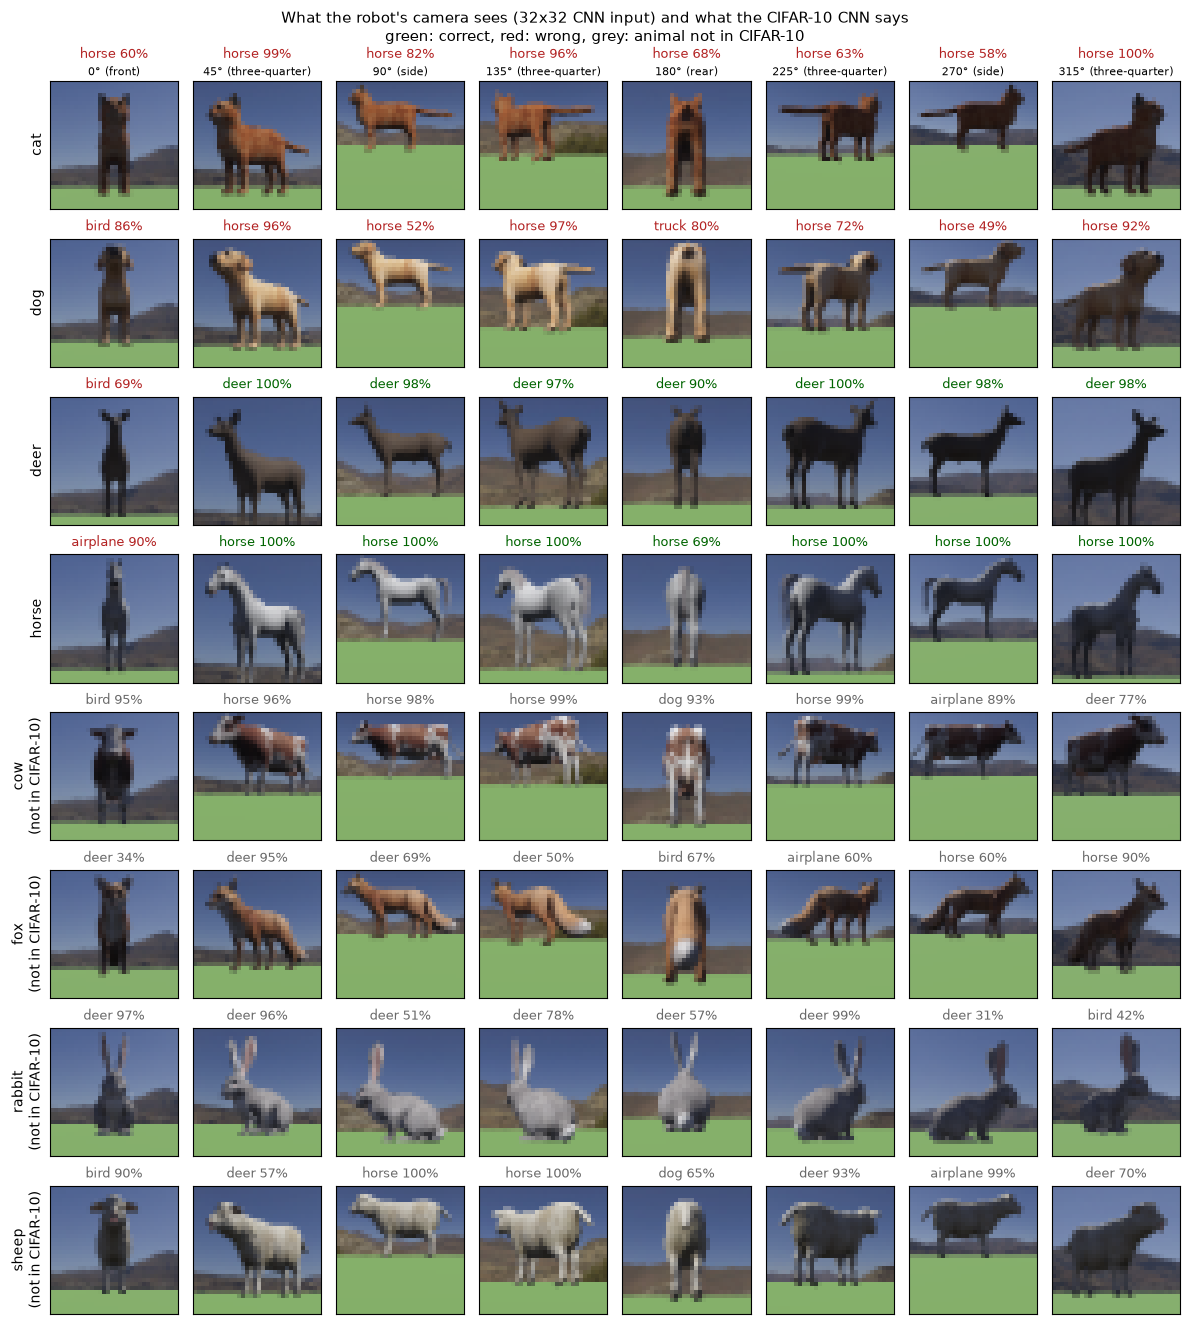

In [3]:
order = ["cat", "dog", "deer", "horse", "cow", "fox", "rabbit", "sheep"]
cols = [0, 45, 90, 135, 180, 225, 270, 315]
fig, axes = plt.subplots(len(order), len(cols), figsize=(12, 13.5))
for i, a in enumerate(order):
    for j, ang in enumerate(cols):
        r = min((x for x in rows if x["animal"] == a), key=lambda x: abs(x["angle"] - ang))  # nearest saved view
        ax = axes[i, j]
        img = cv.cvtColor(cv.imread(str(DATA / f"{r['file']}_crop.png")), cv.COLOR_BGR2RGB)
        ax.imshow(cv.resize(img, (32, 32), interpolation=cv.INTER_AREA)); ax.set_xticks([]); ax.set_yticks([])
        colour = ("darkgreen" if r['correct'] else "firebrick") if r['known'] else "dimgray"
        ax.set_title(f"{r['keras_label']} {r['keras_conf']:.0%}", fontsize=9, color=colour)
        if j == 0:
            ax.set_ylabel(a + ("" if r['known'] else "\n(not in CIFAR-10)"), fontsize=10)
        if i == 0:
            ax.set_xlabel(f"{ang}° ({r['view']})", fontsize=8); ax.xaxis.set_label_position("top")
fig.suptitle("What the robot's camera sees (32x32 CNN input) and what the CIFAR-10 CNN says\n"
             "green: correct, red: wrong, grey: animal not in CIFAR-10", fontsize=11)
plt.tight_layout(); fig.savefig(OUT / "animal_grid.png", dpi=150); plt.show()

## 2. Animals the CNN was never taught

In [4]:
table = {a: Counter(r["keras_label"] for r in rows if r["animal"] == a) for a in order}
for a in order:
    print(f"{a:<7}", ", ".join(f"{k} {n}" for k, n in table[a].most_common()))
print(f"\nUnknown animals called some CIFAR-10 animal class: {pct(sum(r['said_animal'] for r in unknown), len(unknown))}")
conf_known = [r["keras_conf"] for r in known]; conf_unknown = [r["keras_conf"] for r in unknown]
roc = auroc(conf_known, conf_unknown)  # 0.5 = chance, 1.0 = confidence separates them perfectly
print(f"Mean confidence: known {np.mean(conf_known):.2f}, unknown {np.mean(conf_unknown):.2f}; AUROC = {roc:.2f}")
print(f"Unknown animals labelled with >= 90% confidence: {pct(sum(c >= 0.9 for c in conf_unknown), len(unknown))}")

cat     horse 21, deer 2, airplane 1
dog     horse 22, bird 1, truck 1
deer    deer 21, bird 2, horse 1
horse   horse 22, airplane 1, deer 1
cow     horse 13, deer 4, airplane 4, dog 2, bird 1
fox     deer 12, horse 9, airplane 2, bird 1
rabbit  deer 16, airplane 3, bird 3, horse 1, cat 1
sheep   horse 7, deer 7, bird 4, airplane 4, dog 2

Unknown animals called some CIFAR-10 animal class: 83 of 96 (86.5%)
Mean confidence: known 0.88, unknown 0.75; AUROC = 0.71
Unknown animals labelled with >= 90% confidence: 36 of 96 (37.5%)


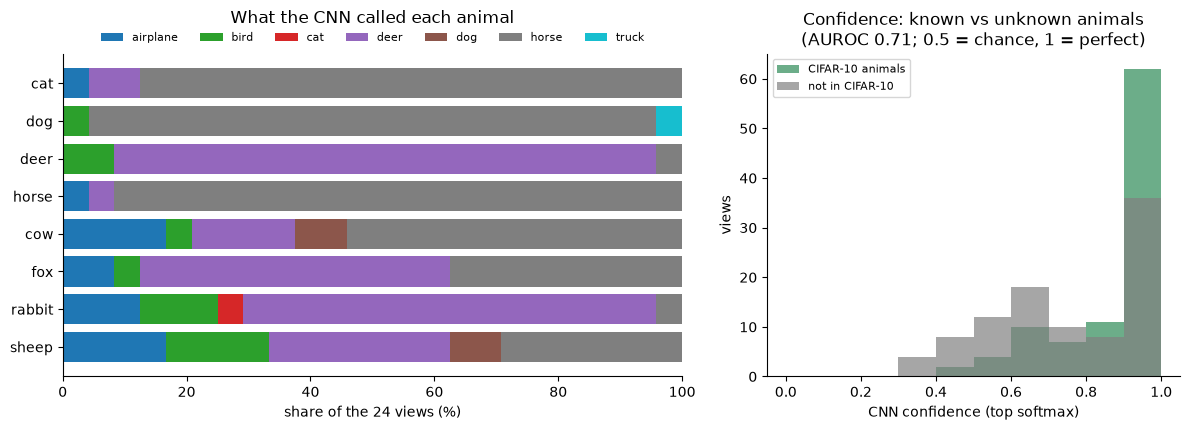

In [5]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.5, 1]})
palette = plt.get_cmap("tab10")
bottom = np.zeros(len(order))
for k, cls in enumerate(CLASS_NAMES):
    share = np.array([100 * table[a][cls] / sum(table[a].values()) for a in order])
    if share.sum() > 0:
        left.barh(order, share, left=bottom, color=palette(k), label=cls); bottom += share
left.invert_yaxis(); left.set_xlabel(f"share of the {N_VIEWS} views (%)"); left.set_xlim(0, 100)
left.legend(ncol=7, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
left.set_title("What the CNN called each animal", pad=22)
bins = np.linspace(0, 1, 11)
right.hist(conf_known, bins=bins, alpha=0.7, label="CIFAR-10 animals", color="seagreen")
right.hist(conf_unknown, bins=bins, alpha=0.7, label="not in CIFAR-10", color="gray")
right.set_xlabel("CNN confidence (top softmax)"); right.set_ylabel("views"); right.legend(fontsize=8)
right.set_title(f"Confidence: known vs unknown animals\n(AUROC {roc:.2f}; 0.5 = chance, 1 = perfect)")
for ax in (left, right): ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); fig.savefig(OUT / "animal_labels_confidence.png", dpi=150); plt.show()

## 3. Animal or scenery? Swapping the background

Same animals, same crops, same pixels on the animal: only the background (sky, hills and grass) is replaced, by plain grey or by a flat indoor-style beige.
If the CNN's answer changes, it was relying on the scenery.

In [6]:
BACKGROUNDS = {"original": None, "grey": (128, 128, 128), "indoor beige": (170, 190, 205)}  # BGR
def swap(r, colour):
    crop = cv.imread(str(DATA / f"{r['file']}_crop.png"))
    if colour is None:
        return crop
    m = cv.imread(str(DATA / f"{r['file']}_mask.png"), cv.IMREAD_GRAYSCALE) > 127
    m = cv.dilate(m.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)[..., None]
    return np.where(m, crop, np.array(colour, np.uint8))

swap_acc = {}
for bg, colour in BACKGROUNDS.items():
    swap_acc[bg] = {}
    for a in ["cat", "dog", "deer", "horse"]:
        rs = [r for r in known if r["animal"] == a]
        labs = [CLASS_NAMES[int(probs_keras(preprocess(swap(r, colour))).argmax())] for r in rs]
        swap_acc[bg][a] = [sum(l == a for l in labs), len(rs), Counter(labs).most_common(1)[0][0]]
    tot = sum(v[0] for v in swap_acc[bg].values())
    print(f"{bg:<13}", "  ".join(f"{a} {v[0]}/{v[1]} (mostly {v[2]})" for a, v in swap_acc[bg].items()), f"| all {pct(tot, len(known))}")

original      cat 0/24 (mostly horse)  dog 0/24 (mostly horse)  deer 21/24 (mostly deer)  horse 22/24 (mostly horse) | all 43 of 96 (44.8%)


grey          cat 4/24 (mostly dog)  dog 12/24 (mostly dog)  deer 4/24 (mostly cat)  horse 20/24 (mostly horse) | all 40 of 96 (41.7%)


indoor beige  cat 7/24 (mostly cat)  dog 5/24 (mostly horse)  deer 0/24 (mostly cat)  horse 18/24 (mostly horse) | all 30 of 96 (31.2%)


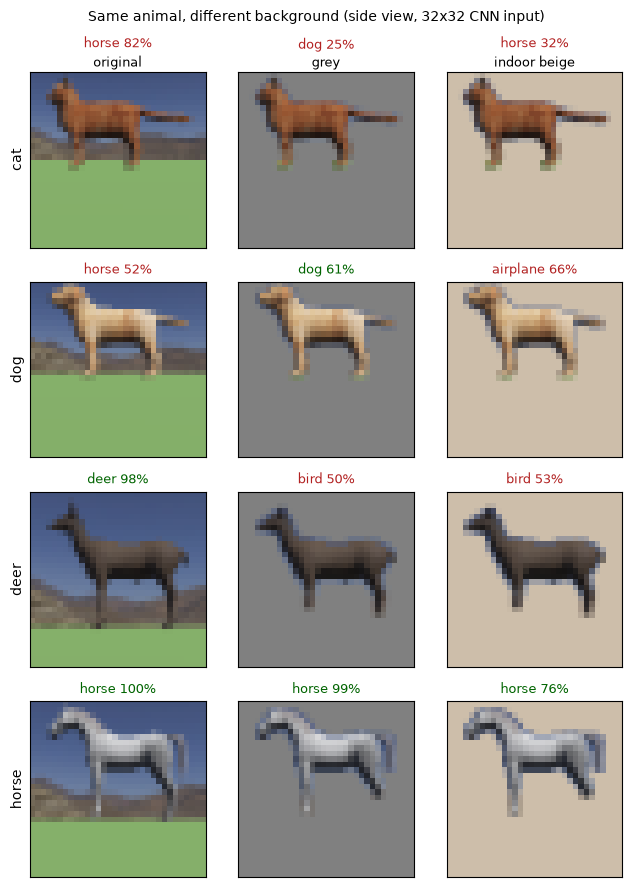

In [7]:
fig, axes = plt.subplots(4, 3, figsize=(6.6, 9))
for i, a in enumerate(["cat", "dog", "deer", "horse"]):
    r = next(x for x in known if x["animal"] == a and x["angle"] == 90)
    for j, (bg, colour) in enumerate(BACKGROUNDS.items()):
        img = swap(r, colour); p = probs_keras(preprocess(img)); k = int(p.argmax())
        ax = axes[i, j]; ax.imshow(cv.resize(cv.cvtColor(img, cv.COLOR_BGR2RGB), (32, 32), interpolation=cv.INTER_AREA))
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{CLASS_NAMES[k]} {p[k]:.0%}", fontsize=9, color="darkgreen" if CLASS_NAMES[k] == a else "firebrick")
        if i == 0: ax.set_xlabel(bg, fontsize=9); ax.xaxis.set_label_position("top")
        if j == 0: ax.set_ylabel(a, fontsize=10)
fig.suptitle("Same animal, different background (side view, 32x32 CNN input)", fontsize=10)
plt.tight_layout(); fig.savefig(OUT / "animal_background_swap.png", dpi=150); plt.show()

In [8]:
summary = dict(views=len(rows), known_views=len(known), known_correct=int(n_ok),
               known_said_animal=int(sum(r["said_animal"] for r in known)), per_animal=per_animal, by_view=by_view,
               unknown_views=len(unknown), unknown_said_animal=int(sum(r["said_animal"] for r in unknown)),
               unknown_labels={a: dict(table[a].most_common()) for a in ["cow", "fox", "rabbit", "sheep"]},
               mean_conf_known=round(float(np.mean(conf_known)), 3), mean_conf_unknown=round(float(np.mean(conf_unknown)), 3),
               auroc_known_vs_unknown=round(roc, 3), unknown_conf_ge_90=int(sum(c >= 0.9 for c in conf_unknown)),
               int8_agreement=round(float(agree), 4), background_swap=swap_acc)
(OUT / "summary.json").write_text(json.dumps(summary, indent=2)); print(json.dumps(summary, indent=2))

{
  "views": 192,
  "known_views": 96,
  "known_correct": 43,
  "known_said_animal": 93,
  "per_animal": {
    "cat": [
      0,
      24,
      "horse"
    ],
    "dog": [
      0,
      24,
      "horse"
    ],
    "deer": [
      21,
      24,
      "deer"
    ],
    "horse": [
      22,
      24,
      "horse"
    ]
  },
  "by_view": {
    "front": [
      6,
      20
    ],
    "three-quarter": [
      8,
      16
    ],
    "side": [
      20,
      40
    ],
    "rear": [
      9,
      20
    ]
  },
  "unknown_views": 96,
  "unknown_said_animal": 83,
  "unknown_labels": {
    "cow": {
      "horse": 13,
      "deer": 4,
      "airplane": 4,
      "dog": 2,
      "bird": 1
    },
    "fox": {
      "deer": 12,
      "horse": 9,
      "airplane": 2,
      "bird": 1
    },
    "rabbit": {
      "deer": 16,
      "airplane": 3,
      "bird": 3,
      "horse": 1,
      "cat": 1
    },
    "sheep": {
      "horse": 7,
      "deer": 7,
      "bird": 4,
      "airplane": 4,
      "dog"

## What this shows

* **Deer and horse are recognised (21 and 22 of 24 views); cat and dog never are (0 of 24), both mostly called "horse".** Nearly every view of a CIFAR-10 animal (93 of 96) is still given *some* animal class.
* **The scenery decides as much as the animal.** The robot's camera sits 3 cm above the ground, so every animal is seen against sky, hills and grass, the setting of CIFAR-10's deer and horse photos. Cats and dogs in CIFAR-10 are mostly close-ups indoors. With the background swapped for grey, the dog is recognised in 12 of 24 views, while the deer drops to 4 of 24: part of "deer" was the landscape. This is shortcut learning, measured on the robot's own images.
* **Front views are hardest** (6 of 20), as with my own car photos.
* **Animals outside CIFAR-10 get confident wrong names** (cow mostly "horse", fox and rabbit "deer"), 37% of them at 90% confidence or more. Confidence separates known from unknown animals only weakly (AUROC 0.71), so it cannot serve as an "unknown animal" alarm on the robot.
* **The int8 robot model gives the same answer as the full model on 97% of views.**

The numbers are in `results/webots_animals/summary.json`; the discussion is in the report.